In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import time
import json
import numpy as np
import nibabel as nib
import multiprocessing
import subprocess
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm import tqdm
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim.lr_scheduler import LambdaLR
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

DRIVE_BASE_DIR = '/content/drive/MyDrive/final_image'
RAW_DIR        = os.path.join(DRIVE_BASE_DIR, 'data/raw')
DRIVE_PROC_DIR = os.path.join(DRIVE_BASE_DIR, 'data/processed')
LOCAL_PROC_DIR = '/content/data/processed'
CKPT_DIR       = os.path.join(DRIVE_BASE_DIR, 'checkpoints')
LOG_DIR        = os.path.join(DRIVE_BASE_DIR, 'logs')
OUT_DIR        = os.path.join(DRIVE_BASE_DIR, 'outputs')

for d in [DRIVE_BASE_DIR, RAW_DIR, DRIVE_PROC_DIR, CKPT_DIR, LOG_DIR, OUT_DIR]:
    os.makedirs(d, exist_ok=True)

Mounted at /content/drive


In [ ]:
N_CASES          = 500
TARGET_H         = 128
TARGET_W         = 128
MIN_TUMOR_PIXELS = 50

def download_brats():
    if len(os.listdir(RAW_DIR)) > 10:
        print("BRATS is already downloaded")
        return
    os.makedirs('/root/.kaggle', exist_ok=True)
    os.system('cp /content/drive/MyDrive/kaggle.json /root/.kaggle/')
    os.system('chmod 600 /root/.kaggle/kaggle.json')
    tar_file = os.path.join(DRIVE_BASE_DIR, 'BraTS2021_Training_Data.tar')
    if not os.path.exists(tar_file):
        print("Downloading the BRATS dataset...")
        subprocess.run(['kaggle', 'datasets', 'download', '-d', 'dschettler8845/brats-2021-task1', '-p', DRIVE_BASE_DIR, '--unzip'], check=True)
    subprocess.run(['tar', '-xf', tar_file, '-C', RAW_DIR], check=True)

def normalize(vol):
    mask = vol > 0
    if mask.sum() == 0: return vol.astype(np.float32)
    mean, std = vol[mask].mean(), vol[mask].std() + 1e-8
    out = np.zeros_like(vol, dtype=np.float32)
    out[mask] = (vol[mask] - mean) / std
    return out

def center_crop_pad(sl, size=(128, 128)):
    h, w = sl.shape
    sh, sw = size
    ch, cw = max((h - sh) // 2, 0), max((w - sw) // 2, 0)
    sl = sl[ch:ch+sh, cw:cw+sw]
    ph, pw = sh - sl.shape[0], sw - sl.shape[1]
    if ph > 0 or pw > 0: sl = np.pad(sl, ((0, ph), (0, pw)), mode='constant')
    return sl

def remap_brats_labels(seg):
    out = np.zeros_like(seg, dtype=np.float32)
    out[seg == 1] = 1.0; out[seg == 2] = 2.0; out[seg == 4] = 3.0
    return out

def generate_pseudo_healthy(img_slice, seg_slice):
    tumor_mask = seg_slice > 0
    if tumor_mask.sum() == 0: return img_slice
    flipped_slice = np.flipud(img_slice)
    flipped_mask  = np.flipud(tumor_mask)
    valid_flip_mask = tumor_mask & (~flipped_mask)
    pseudo_slice = np.where(valid_flip_mask, flipped_slice, img_slice)
    double_tumor_mask = tumor_mask & flipped_mask
    if double_tumor_mask.sum() > 0:
        healthy_brain_mask = (img_slice > 0) & (~tumor_mask)
        mean_healthy = img_slice[healthy_brain_mask].mean() if healthy_brain_mask.sum() > 0 else 0
        pseudo_slice[double_tumor_mask] = mean_healthy
    blurred_pseudo = gaussian_filter(pseudo_slice, sigma=2.0)
    return np.where(tumor_mask, blurred_pseudo, img_slice).astype(np.float32)

def process_case(case_dir, case_name, target_size):
    try:
        t1    = nib.load(os.path.join(case_dir, f"{case_name}_t1.nii.gz")).get_fdata().astype(np.float32)
        t1ce  = nib.load(os.path.join(case_dir, f"{case_name}_t1ce.nii.gz")).get_fdata().astype(np.float32)
        t2    = nib.load(os.path.join(case_dir, f"{case_name}_t2.nii.gz")).get_fdata().astype(np.float32)
        flair = nib.load(os.path.join(case_dir, f"{case_name}_flair.nii.gz")).get_fdata().astype(np.float32)
        seg   = nib.load(os.path.join(case_dir, f"{case_name}_seg.nii.gz")).get_fdata().astype(np.float32)
    except FileNotFoundError: return None

    t1_n, t1ce_n, t2_n, flair_n = normalize(t1), normalize(t1ce), normalize(t2), normalize(flair)
    tumor_slices = np.where(seg.sum(axis=(0, 1)) > MIN_TUMOR_PIXELS)[0]
    if len(tumor_slices) == 0: return None

    processed = []
    for sl_idx in tumor_slices:
        t1_sl    = center_crop_pad(t1_n[:, :, sl_idx], target_size)
        t1ce_sl  = center_crop_pad(t1ce_n[:, :, sl_idx], target_size)
        t2_sl    = center_crop_pad(t2_n[:, :, sl_idx], target_size)
        flair_sl = center_crop_pad(flair_n[:, :, sl_idx], target_size)
        seg_sl   = center_crop_pad(seg[:, :, sl_idx], target_size)
        pseudo_normal_sl = generate_pseudo_healthy(t1ce_sl, seg_sl)
        seg_remapped = remap_brats_labels(seg_sl)
        processed.append(np.stack([t1_sl, t1ce_sl, t2_sl, flair_sl, pseudo_normal_sl, seg_remapped], axis=0).astype(np.float32))
    return np.stack(processed, axis=0)

def process_wrapper(args):
    case, raw_dir, proc_dir, tgt_size = args
    out_path = os.path.join(proc_dir, f"{case}.npy")
    if os.path.exists(out_path): return 1, 0
    result = process_case(os.path.join(raw_dir, case), case, tgt_size)
    if result is None: return 0, 1
    np.save(out_path, result)
    return 1, 0

In [ ]:
download_brats()
all_cases = sorted([d for d in os.listdir(RAW_DIR) if os.path.isdir(os.path.join(RAW_DIR, d))])[:N_CASES]
args_list = [(case, RAW_DIR, DRIVE_PROC_DIR, (TARGET_H, TARGET_W)) for case in all_cases]

with ThreadPoolExecutor(max_workers=multiprocessing.cpu_count()) as executor:
    futures = [executor.submit(process_wrapper, a) for a in args_list]
    for _ in tqdm(as_completed(futures), total=len(all_cases), desc="Preprocessing.."): pass
print(f"Patient count: {len(os.listdir(DRIVE_PROC_DIR))}")

BRATS is already downloaded


Preprocessing..: 100%|██████████| 500/500 [00:00<00:00, 13813.68it/s]

Patient count: 500


In [ ]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter

class ResidualAnomalyModule(nn.Module):
    """
    Residual-based anomaly detector that uses the pseudo-healthy image
    already produced by the SRN to derive a pixel-wise anomaly score.

    Pipeline:
        1. Compute absolute residual:  R = |T1ce − refined_normal|
        2. Pass R through a small 3-layer conv to learn a refined anomaly map A.
        3. Threshold A to build a soft binary prior  P ∈ [0,1].
        4. Boost segmentation logits:  logits_out = logits * (1 + α·P)
           → background class (0) is NOT boosted so the model stays conservative
             in regions with no anomaly signal.

    Args:
        in_ch    : input channels for the refinement conv (default 1 = residual map)
        mid_ch   : intermediate channels (keep small; this is a lightweight module)
        alpha    : logit boost strength.  0.5 is a safe default.
    """
    def __init__(self, in_ch: int = 1, mid_ch: int = 8, alpha: float = 0.5):
        super().__init__()
        self.alpha = alpha
        # Small conv stack: residual → refined anomaly map (still single channel)
        self.refine = nn.Sequential(
            nn.Conv2d(in_ch, mid_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(mid_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(mid_ch, mid_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(mid_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(mid_ch, 1, kernel_size=1, bias=False),
            nn.Sigmoid(),   # anomaly score in [0, 1]
        )

    def forward(self, logits, t1ce, refined_normal):
        """
        Args:
            logits         : (B, n_classes, H, W)  raw segmentation logits
            t1ce           : (B, 1, H, W)           real T1ce image
            refined_normal : (B, 1, H, W)           SRN pseudo-healthy image

        Returns:
            boosted_logits : (B, n_classes, H, W)  anomaly-aware logits
            anomaly_score  : (B, 1, H, W)          per-pixel anomaly score [0,1]
        """
        # Step 1: absolute residual (detached — no gradient through the anomaly path)
        residual = torch.abs(t1ce - refined_normal.detach())

        # Step 2: learned refinement of the raw residual
        anomaly_score = self.refine(residual)           # (B, 1, H, W)

        # Step 3: build prior — high anomaly → encourage non-background prediction
        # Only boost classes 1-3; leave class 0 (background) untouched.
        boost = torch.ones_like(logits)
        boost[:, 1:, :, :] = 1.0 + self.alpha * anomaly_score

        boosted_logits = logits * boost

        return boosted_logits, anomaly_score

class Conv3x3(nn.Module):
    def __init__(self, inc, outc, stride=1):
        super().__init__()
        self.conv = nn.Conv2d(inc, outc, 3, stride, padding=1, bias=False)
        self.bn   = nn.BatchNorm2d(outc)
        self.relu = nn.LeakyReLU(0.2, inplace=True)
    def forward(self, x): return self.relu(self.bn(self.conv(x)))

class SymmetryRefinementNetwork(nn.Module):
    """Symmetry-Aware Refinement Network (SRN) - Replaces IntroVAE"""
    def __init__(self, in_ch=2, mid_ch=16):
        super().__init__()
        self.conv1 = Conv3x3(in_ch, mid_ch)
        self.conv2 = Conv3x3(mid_ch, mid_ch)
        self.conv3 = nn.Conv2d(mid_ch, 1, kernel_size=3, padding=1)
        self.tanh = nn.Tanh()
    def forward(self, rough_pseudo, t1ce_guide):
        x = torch.cat([rough_pseudo, t1ce_guide], dim=1)
        residual = self.tanh(self.conv3(self.conv2(self.conv1(x))))
        return rough_pseudo + residual

class LightAttention(nn.Module):
    def __init__(self, dim, heads=2):
        super().__init__()
        self.heads, self.dim_head = heads, max(dim // heads, 16)
        inner = self.dim_head * heads
        self.to_q, self.to_k, self.to_v = nn.Linear(dim, inner, bias=False), nn.Linear(dim, inner, bias=False), nn.Linear(dim, inner, bias=False)
        self.proj, self.pos_emb = nn.Linear(inner, dim), nn.Conv2d(dim, dim, 3, 1, 1, bias=False, groups=dim)
        self.scale = nn.Parameter(torch.ones(heads, 1, 1))
    def forward(self, x):
        B, C, H, W = x.shape
        tokens = x.permute(0, 2, 3, 1).reshape(B, H * W, C)
        Q, K, V = self.to_q(tokens), self.to_k(tokens), self.to_v(tokens)
        Q = F.normalize(Q.reshape(B, H * W, self.heads, self.dim_head).permute(0, 2, 3, 1), dim=-1)
        K = F.normalize(K.reshape(B, H * W, self.heads, self.dim_head).permute(0, 2, 3, 1), dim=-1)
        V = V.reshape(B, H * W, self.heads, self.dim_head).permute(0, 2, 3, 1)
        attn = ((K @ Q.transpose(-2, -1)) * self.scale).softmax(dim=-1)
        out = self.proj((attn @ V).permute(0, 3, 1, 2).reshape(B, H * W, -1)).view(B, H, W, C).permute(0, 3, 1, 2)
        return out + self.pos_emb(x)

class LightTransformer(nn.Module):
    def __init__(self, dim, heads=2):
        super().__init__()
        self.attn = LightAttention(dim, heads=heads)
        self.ff   = nn.Sequential(nn.Conv2d(dim, dim * 2, 1, bias=False), nn.GELU(), nn.Conv2d(dim * 2, dim * 2, 3, 1, 1, bias=False, groups=dim * 2), nn.GELU(), nn.Conv2d(dim * 2, dim, 1, bias=False))
    def forward(self, x): return self.ff(self.attn(x) + x) + (self.attn(x) + x)

class AttentionGate(nn.Module):
    def __init__(self, ch):
        super().__init__()
        midc = max(ch // 2, 8)
        self.gconv, self.xconv, self.psi = nn.Conv2d(ch, midc, 1, bias=False), nn.Conv2d(ch, midc, 1, bias=False), nn.Conv2d(midc, 1, 1, bias=False)
    def forward(self, g, x):
        attn = torch.sigmoid(self.psi(F.relu(-self.gconv(g) * self.xconv(x))))
        return x * attn, attn

class SimplifiedNORMNET(nn.Module):
    def __init__(self, in_ch=1, midc=8, stages=3):
        super().__init__()
        self.inconv = Conv3x3(in_ch, midc)
        self.enc, self.dec = nn.ModuleList(), nn.ModuleList()
        ch = midc
        for _ in range(stages): self.enc.append(Conv3x3(ch, ch * 2, stride=2)); ch *= 2
        for _ in range(stages): self.dec.append(nn.ModuleList([nn.ConvTranspose2d(ch, ch // 2, 2, 2), Conv3x3(ch, ch // 2)])); ch //= 2
    def forward(self, normal_img):
        x = self.inconv(normal_img)
        enc_feas = []
        for layer in self.enc: x = layer(x); enc_feas.append(x)
        fea, dec_feas = enc_feas[-1], []
        for i, (up, merge) in enumerate(self.dec):
            fea = up(fea)
            if i < len(enc_feas) - 1: fea = merge(torch.cat([fea, enc_feas[-2 - i]], dim=1))
            dec_feas.append(fea)
        return dec_feas

class SEGNET(nn.Module):
    def __init__(self, inc=4, outc=4, midc=8, stages=3):
        super().__init__()
        self.inc, self.stages = inc, stages
        self.refinement_net = SymmetryRefinementNetwork(in_ch=2, mid_ch=16)
        self.normnet = SimplifiedNORMNET(in_ch=1, midc=midc, stages=stages)
        self.inconvs = nn.ModuleList([Conv3x3(1, midc) for _ in range(inc)])
        self.encs = nn.ModuleList()
        for _ in range(inc):
            enc_layers, ch = nn.ModuleList(), midc
            for _ in range(stages): enc_layers.append(Conv3x3(ch, ch * 2, stride=2)); ch *= 2
            self.encs.append(enc_layers)
        self.fusion = nn.ModuleList()
        ch = midc
        for _ in range(stages):
            ch *= 2
            self.fusion.append(nn.Sequential(LightTransformer(dim=inc * ch, heads=max((inc * ch) // 32, 2)), Conv3x3(inc * ch, ch)))
        self.dec, self.fam, self.convouts = nn.ModuleList(), nn.ModuleList(), nn.ModuleList()
        for _ in range(stages):
            self.dec.append(nn.ModuleList([nn.ConvTranspose2d(ch, ch // 2, 2, 2), Conv3x3(ch, ch // 2)]))
            ch //= 2
            self.fam.append(AttentionGate(ch))
            self.convouts.append(nn.Conv2d(ch, outc, 1))
        self.anomaly_module = ResidualAnomalyModule(in_ch=1, mid_ch=8, alpha=0.5)  # ← buraya

    def forward(self, x, rough_normal):
        t1ce_guide = x[:, 1:2, :, :]
        refined_normal = self.refinement_net(rough_normal, t1ce_guide)
        norm_feas = self.normnet(refined_normal)
        xin = torch.chunk(x, self.inc, dim=1)
        enc_feas = []
        for i in range(self.inc):
            feat, feas = self.inconvs[i](xin[i]), []
            for layer in self.encs[i]: feat = layer(feat); feas.append(feat)
            enc_feas.append(feas)
        fus_feas = []
        for k in range(self.stages): fus_feas.append(self.fusion[k](torch.cat([enc_feas[i][k] for i in range(self.inc)], dim=1)))
        outs, attn_maps, fea = [], [], fus_feas[-1]
        for i, (up, merge) in enumerate(self.dec):
            fea = up(fea)
            if i < len(fus_feas) - 1: fea = merge(torch.cat([fea, fus_feas[-2 - i]], dim=1))
            fea, attn = self.fam[i](norm_feas[i], fea)
            attn_maps.append(attn); outs.append(self.convouts[i](fea))

        # Anomaly score computed in both training and inference
        # Training: used as loss weight (no logit modification — stable gradients)
        # Inference: used to boost non-background logits
        _, anomaly_score = self.anomaly_module(
            outs[-1], x[:, 1:2, :, :], refined_normal
        )

        if self.training:
            return (outs, attn_maps, anomaly_score)
        else:
            boosted, anomaly_score = self.anomaly_module(
                outs[-1], x[:, 1:2, :, :], refined_normal
            )
            return (boosted, attn_maps, anomaly_score)

class DiceCELoss(nn.Module):
    def __init__(self, beta: float = 0.3):
        super().__init__()
        self.ce   = nn.CrossEntropyLoss(reduction='none')
        self.beta = beta  # anomaly weight strength — keep small for stability

    def forward(self, pred, target, anomaly_score=None):
        with torch.no_grad():
            y_onehot = torch.zeros_like(pred).scatter_(1, target.long(), 1)
        p = torch.softmax(pred, dim=1)
        axes = [0] + list(range(2, p.ndim))
        tp = (p * y_onehot).sum(axes)
        fp = (p * (1 - y_onehot)).sum(axes)
        fn = ((1 - p) * y_onehot).sum(axes)
        dice_loss = -((2 * tp + 1e-5) / (2 * tp + fp + fn + 1e-5))[1:].mean()

        ce_map = self.ce(pred, target.squeeze(1).long())  # (B, H, W)

        if anomaly_score is not None:
            # Upscale anomaly score to match logit resolution if needed
            if anomaly_score.shape[-2:] != ce_map.shape[-2:]:
                anomaly_score = F.interpolate(
                    anomaly_score, size=ce_map.shape[-2:],
                    mode='bilinear', align_corners=False
                )
            # Weight CE loss: anomaly regions penalised more heavily
            weight = 1.0 + self.beta * anomaly_score.squeeze(1).detach()
            ce_loss = (ce_map * weight).mean()
        else:
            ce_loss = ce_map.mean()

        return dice_loss + ce_loss

In [ ]:
class BraTSDataset(Dataset):
    def __init__(self, proc_dir, case_list, augment=False):
        self.samples = []
        self.augment = augment
        for case in case_list:
            path = os.path.join(proc_dir, f"{case}.npy")
            if os.path.exists(path):
                n_slices = np.load(path, mmap_mode='r').shape[0]
                for sl_idx in range(n_slices): self.samples.append((path, sl_idx))

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        path, sl_idx = self.samples[idx]
        sl = np.load(path)[sl_idx]
        t1, t1ce, t2, flair, normal, seg = sl[0], sl[1], sl[2], sl[3], sl[4], np.clip(sl[5].astype(np.int64), 0, 3)

        if self.augment:
            if np.random.rand() > 0.5:
                t1, t1ce, t2, flair, normal, seg = [np.fliplr(a).copy() for a in [t1, t1ce, t2, flair, normal, seg]]
            if np.random.rand() > 0.5:
                t1, t1ce, t2, flair, normal, seg = [np.flipud(a).copy() for a in [t1, t1ce, t2, flair, normal, seg]]

        x = torch.from_numpy(np.stack([t1, t1ce, t2, flair], axis=0).astype(np.float32))
        return x, torch.from_numpy(normal[np.newaxis].astype(np.float32)), torch.from_numpy(seg[np.newaxis].astype(np.int64))

class PolyScheduler(LambdaLR):
    def __init__(self, optimizer, t_total, exponent=0.9, last_epoch=-1):
        self.t_total, self.exponent = t_total, exponent
        super().__init__(optimizer, self.lr_lambda, last_epoch=last_epoch)
    def lr_lambda(self, step): return (1 - step / self.t_total) ** self.exponent

def compute_dice(pred_logits, target):
    pred = pred_logits.argmax(dim=1)
    target_sq = target.squeeze(1)
    scores = []
    for cls in range(1, 4):
        p, t = (pred == cls).float(), (target_sq == cls).float()
        union = p.sum() + t.sum()
        if union > 0: scores.append(((2 * (p * t).sum() + 1e-5) / (union + 1e-5)).item())
    return float(np.mean(scores)) if scores else 0.0

In [ ]:
EPOCHS = 60
BATCH_SIZE = 4
LR = 2e-4

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

import shutil
if not os.path.exists(LOCAL_PROC_DIR) or len(os.listdir(LOCAL_PROC_DIR)) < len(os.listdir(DRIVE_PROC_DIR)):
    print("Data is being copied to the Colab disk for training speed... PLEASE WAIT (This may take approximately 2-5 minutes)")
    shutil.copytree(DRIVE_PROC_DIR, LOCAL_PROC_DIR, dirs_exist_ok=True)
    print("Copying complete! Data is ready.")
else:
    print("The data is already available on the Colab disk. The copying was skipped.")

Device: cuda
Data is being copied to the Colab disk for training speed... PLEASE WAIT (This may take approximately 2-5 minutes)
Copying complete! Data is ready.


In [ ]:
all_cases = sorted([f.replace('.npy', '') for f in os.listdir(LOCAL_PROC_DIR) if f.endswith('.npy')])
train_val, test_cases = train_test_split(all_cases, test_size=0.15, random_state=42)
train_cases, val_cases = train_test_split(train_val, test_size=0.15/0.85, random_state=42)

train_loader = DataLoader(BraTSDataset(LOCAL_PROC_DIR, train_cases, True), batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
val_loader = DataLoader(BraTSDataset(LOCAL_PROC_DIR, val_cases, False), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

model = SEGNET().to(device)
optimizer = optim.Adam(model.parameters(), lr=LR)
scheduler = PolyScheduler(optimizer, t_total=EPOCHS * len(train_loader))
criterion = DiceCELoss()

In [ ]:
best_dice = 0.0
log_path = os.path.join(LOG_DIR, 'train_log.csv')
if not os.path.exists(log_path):
    with open(log_path, 'w') as f: f.write("epoch,train_loss,train_dice,val_loss,val_dice,lr\n")

from tqdm import tqdm
for epoch in range(EPOCHS):
    model.train()
    tr_loss, tr_dice = 0, 0
    pbar_train = tqdm(train_loader, desc=f"Epoch {epoch+1:02d}/{EPOCHS} [Train]")
    for x, normal, target in pbar_train:
        x, normal, target = x.to(device), normal.to(device), target.to(device)
        outs, _, anomaly_score = model(x, normal)
        loss = sum(
            w * criterion(
                out,
                F.interpolate(target.float(), size=(out.shape[2], out.shape[3]), mode='nearest').long(),
                anomaly_score if j == len(outs) - 1 else None  # only last output gets weighted
            )
            for j, (w, out) in enumerate(zip([0.5, 0.75, 1.0], outs))
        )
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        l_val = loss.item()
        d_val = compute_dice(outs[-1], target)
        tr_loss += l_val
        tr_dice += d_val
        pbar_train.set_postfix({'Loss': f"{l_val:.3f}", 'Dice': f"{d_val:.3f}"})
    scheduler.step()

    model.eval()
    val_loss, val_dice = 0, 0
    pbar_val = tqdm(val_loader, desc=f"Epoch {epoch+1:02d}/{EPOCHS} [Val]  ", leave=False)
    with torch.no_grad():
        for x, normal, target in pbar_val:
            x, normal, target = x.to(device), normal.to(device), target.to(device)
            out, _, _anomaly = model(x, normal)
            val_loss += criterion(out, target, anomaly_score=None).item()
            val_dice += compute_dice(out, target)

    tr_l, tr_d = tr_loss/len(train_loader), tr_dice/len(train_loader)
    va_l, va_d = val_loss/len(val_loader), val_dice/len(val_loader)
    print(f"Result -> Train Loss: {tr_l:.4f} | Train Dice: {tr_d:.4f} || Val Loss: {va_l:.4f} | Val Dice: {va_d:.4f}\n")

    with open(log_path, 'a') as f: f.write(f"{epoch},{tr_l:.4f},{tr_d:.4f},{va_l:.4f},{va_d:.4f},{LR}\n")

    # Save best model
    if va_d > best_dice:
        best_dice = va_d
        torch.save({'epoch': epoch, 'model': model.state_dict(), 'best_dice': best_dice},
                   os.path.join(CKPT_DIR, 'best_model.pth'))
        print(f"*** New Best Model Saved (Val Dice: {best_dice:.4f}) ***\n")

    # Save last epoch checkpoint (overwritten every epoch)
    torch.save({'epoch': epoch, 'model': model.state_dict(), 'val_dice': va_d},
               os.path.join(CKPT_DIR, 'last_model.pth'))


Mean_WT_Dice: 0.9800
Mean_TC_Dice: 0.8287
Mean_ET_Dice: 0.8102


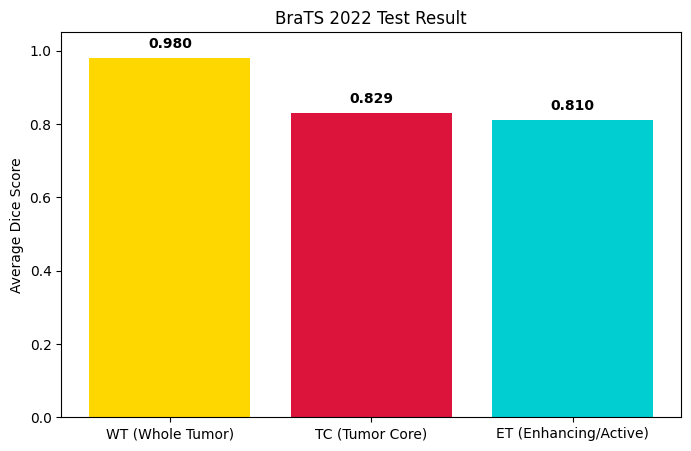

In [ ]:
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
import matplotlib.patches as mpatches
import torch.nn.functional as F

test_loader = DataLoader(BraTSDataset(LOCAL_PROC_DIR, test_cases, False), batch_size=1, shuffle=False)
best_model_path = os.path.join(CKPT_DIR, 'last_model.pth')

if os.path.exists(best_model_path):
    model.load_state_dict(torch.load(best_model_path)['model'])
    model.eval()

    brats_dices = {'WT (Whole Tumor)': [], 'TC (Tumor Core)': [], 'ET (Enhancing/Active)': []}

    with torch.no_grad():
        for x, normal, target in test_loader:
            x, normal, target = x.to(device), normal.to(device), target.to(device)
            out = model(x, normal)
            pred = out[0].argmax(dim=1).squeeze(0).cpu().numpy()
            tgt = target.squeeze(0).squeeze(0).cpu().numpy()

            # BraTS Rule:
            # 1: Necrosis, 2: Edema, 3: Active Tumor

            # WT (Whole Tumor) = 1 + 2 + 3
            p_wt, t_wt = (pred > 0).astype(float), (tgt > 0).astype(float)

            # TC (Tumor Core) = 1 + 3 (Necrosis + Active Tumor)
            p_tc = ((pred == 1) | (pred == 3)).astype(float)
            t_tc = ((tgt == 1) | (tgt == 3)).astype(float)

            # ET (Enhancing Tumor) = 3 (Active Tumor)
            p_et, t_et = (pred == 3).astype(float), (tgt == 3).astype(float)

            for p, t, name in zip([p_wt, p_tc, p_et], [t_wt, t_tc, t_et], ['WT (Whole Tumor)', 'TC (Tumor Core)', 'ET (Enhancing/Active)']):
                union = p.sum() + t.sum()
                if union > 0:
                    brats_dices[name].append(float((2 * (p * t).sum() + 1e-5) / (union + 1e-5)))

    metrics_report = {
        'Mean_WT_Dice': np.mean(brats_dices['WT (Whole Tumor)']),
        'Mean_TC_Dice': np.mean(brats_dices['TC (Tumor Core)']),
        'Mean_ET_Dice': np.mean(brats_dices['ET (Enhancing/Active)'])
    }

    json_path = os.path.join(OUT_DIR, 'brats_standard_metrics.json')
    with open(json_path, 'w') as f:
        json.dump(metrics_report, f, indent=4)
    for k, v in metrics_report.items():
        print(f"{k}: {v:.4f}")

    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(['WT (Whole Tumor)', 'TC (Tumor Core)', 'ET (Enhancing/Active)'], metrics_report.values(), color=['#FFD700', '#DC143C', '#00CED1'])
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Average Dice Score')
    ax.set_title('BraTS 2022 Test Result')
    for bar in bars:
        yval = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f'{yval:.3f}', ha='center', va='bottom', fontweight='bold')
    plt.show()

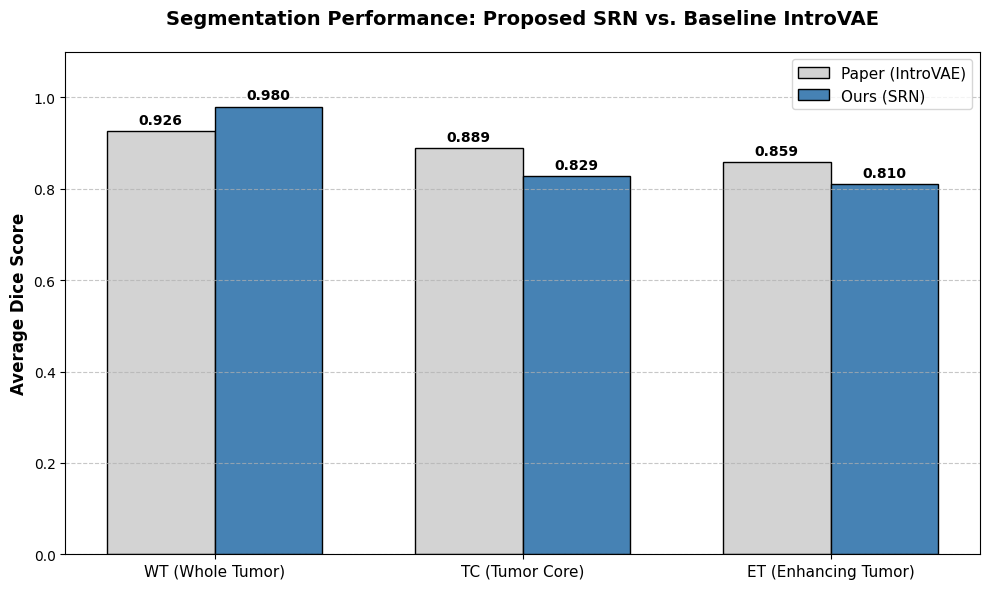

In [ ]:
def plot_academic_comparison():
    json_path = os.path.join(OUT_DIR, 'brats_standard_metrics.json')
    if not os.path.exists(json_path):
        print("Metrics file not found. Please run the evaluation cell first.")
        return

    with open(json_path, 'r') as f:
        our_metrics = json.load(f)

    labels = ['WT (Whole Tumor)', 'TC (Tumor Core)', 'ET (Enhancing Tumor)']
    paper_scores = [0.926, 0.889, 0.859]
    our_scores = [our_metrics['Mean_WT_Dice'], our_metrics['Mean_TC_Dice'], our_metrics['Mean_ET_Dice']]

    x = np.arange(len(labels))
    width = 0.35

    fig, ax = plt.subplots(figsize=(10, 6))
    rects1 = ax.bar(x - width/2, paper_scores, width, label='Paper (IntroVAE)', color='lightgray', edgecolor='black')
    rects2 = ax.bar(x + width/2, our_scores, width, label='Ours (SRN)', color='steelblue', edgecolor='black')

    ax.set_ylabel('Average Dice Score', fontsize=12, fontweight='bold')
    ax.set_title('Segmentation Performance: Proposed SRN vs. Baseline IntroVAE', fontsize=14, fontweight='bold', pad=20)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=11)
    ax.set_ylim(0, 1.1)
    ax.legend(fontsize=11)

    # Attach a text label above each bar displaying its height
    def autolabel(rects):
        for rect in rects:
            height = rect.get_height()
            ax.annotate(f'{height:.3f}',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3),  # 3 points vertical offset
                        textcoords="offset points",
                        ha='center', va='bottom', fontweight='bold')

    autolabel(rects1)
    autolabel(rects2)

    ax.yaxis.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

plot_academic_comparison()

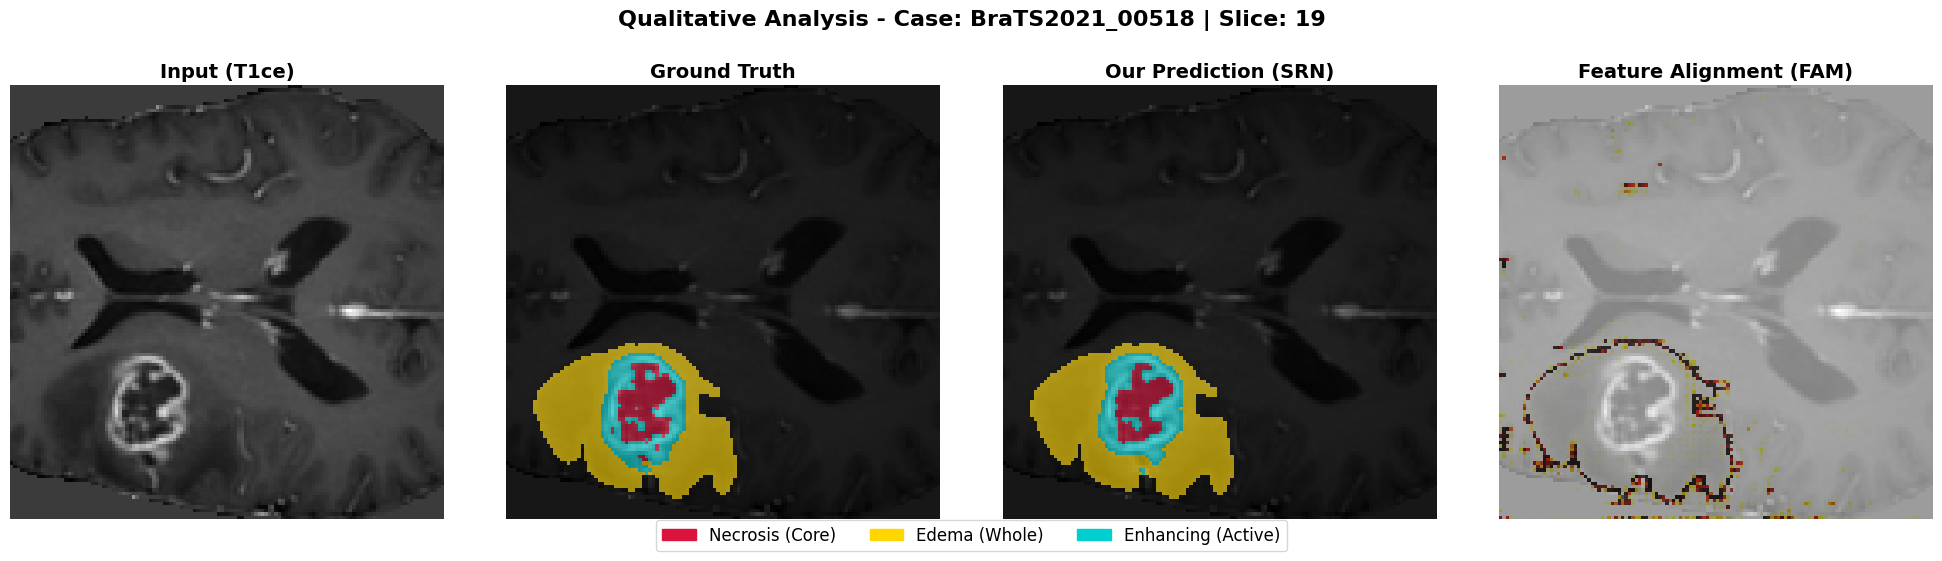

In [ ]:
def show_prediction_visuals(slice_idx=None):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    best_model_path = os.path.join(CKPT_DIR, 'best_model.pth')

    if not os.path.exists(best_model_path):
        print("Model checkpoint not found.")
        return

    model = SEGNET().to(device)
    model.load_state_dict(torch.load(best_model_path, map_location=device)['model'])
    model.eval()

    # Load a sample from test set
    test_case = test_cases[0] # Pick the first test case
    data = np.load(os.path.join(LOCAL_PROC_DIR, f"{test_case}.npy"))

    seg_channel = data[:, 5, :, :]
    tumor_slices = np.where(seg_channel.sum(axis=(1, 2)) > 150)[0]

    if len(tumor_slices) == 0:
        print("No significant tumor found in this sample.")
        return

    s_idx = slice_idx if slice_idx else int(np.random.choice(tumor_slices))
    sl = data[s_idx]

    t1, t1ce, t2, flair, normal, seg = sl[0], sl[1], sl[2], sl[3], sl[4], sl[5].astype(np.int64)

    x = torch.from_numpy(np.stack([t1, t1ce, t2, flair], axis=0)[np.newaxis].astype(np.float32)).to(device)
    n_t = torch.from_numpy(normal[np.newaxis, np.newaxis].astype(np.float32)).to(device)

    with torch.no_grad():
        out, attns, _ = model(x, n_t)

    pred = out.squeeze(0).argmax(dim=0).cpu().numpy()
    attn_map = attns[-1].squeeze().cpu().numpy()

    # Normalize attention map
    attn_norm = (attn_map - attn_map.min()) / (attn_map.max() - attn_map.min() + 1e-8)

    # Color Mapping function
    def apply_colors(label_map):
        rgb = np.zeros((128, 128, 3), dtype=np.float32)
        rgb[label_map == 1] = [0.86, 0.08, 0.24] # Crimson (Necrosis)
        rgb[label_map == 2] = [1.00, 0.84, 0.00] # Gold (Edema)
        rgb[label_map == 3] = [0.00, 0.81, 0.82] # Cyan (Active Tumor)
        return rgb

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    # 1. Modality (T1ce)
    axes[0].imshow(t1ce, cmap='gray')
    axes[0].set_title('Input (T1ce)', fontsize=14, fontweight='bold')
    axes[0].axis('off')

    # 2. Ground Truth
    axes[1].imshow(t1ce, cmap='gray')
    axes[1].imshow(apply_colors(seg), alpha=0.6)
    axes[1].set_title('Ground Truth', fontsize=14, fontweight='bold')
    axes[1].axis('off')

    # 3. Prediction
    axes[2].imshow(t1ce, cmap='gray')
    axes[2].imshow(apply_colors(pred), alpha=0.6)
    axes[2].set_title('Our Prediction (SRN)', fontsize=14, fontweight='bold')
    axes[2].axis('off')

    # 4. Attention Map
    axes[3].imshow(t1ce, cmap='gray')
    axes[3].imshow(attn_norm, cmap='hot', alpha=0.5)
    axes[3].set_title('Feature Alignment (FAM)', fontsize=14, fontweight='bold')
    axes[3].axis('off')

    # Legend
    patches = [
        mpatches.Patch(color=[0.86, 0.08, 0.24], label='Necrosis (Core)'),
        mpatches.Patch(color=[1.00, 0.84, 0.00], label='Edema (Whole)'),
        mpatches.Patch(color=[0.00, 0.81, 0.82], label='Enhancing (Active)')
    ]
    fig.legend(handles=patches, loc='lower center', ncol=3, fontsize=12, bbox_to_anchor=(0.5, -0.05))

    plt.suptitle(f"Qualitative Analysis - Case: {test_case} | Slice: {s_idx}", fontsize=16, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()

show_prediction_visuals()

Extracting advanced metrics (Dice, Sensitivity, Precision) across the test set...


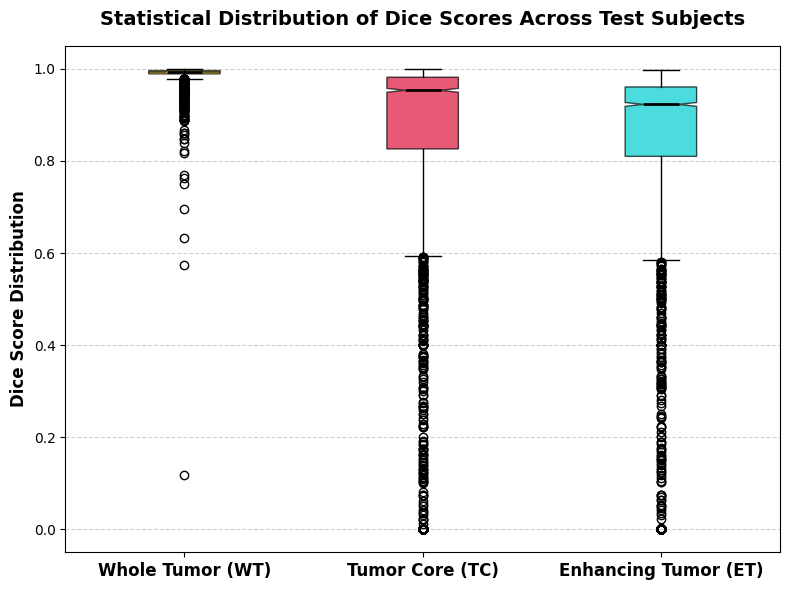

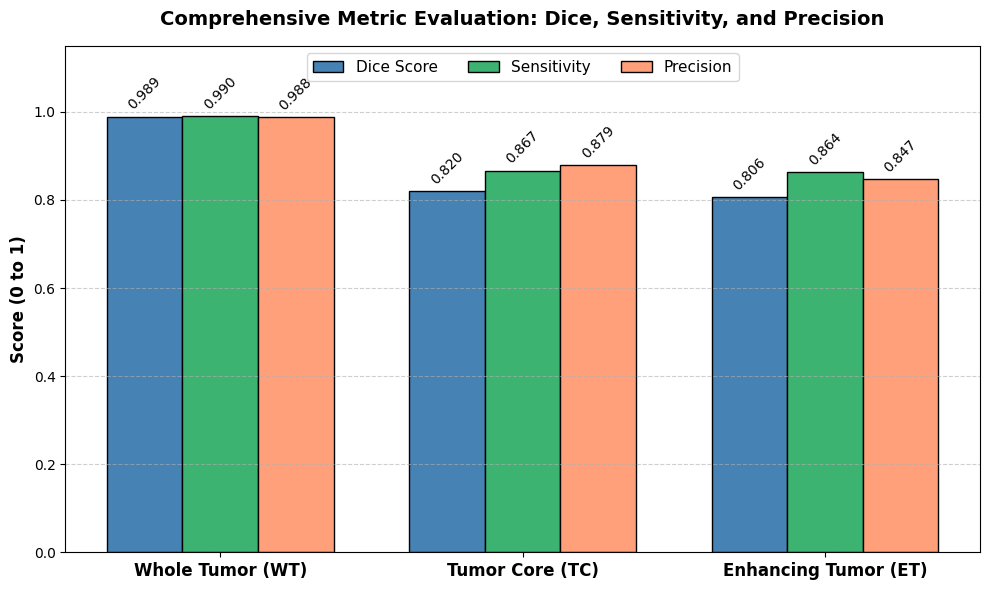

In [ ]:
def evaluate_advanced_metrics():
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    best_model_path = os.path.join(CKPT_DIR, 'best_model.pth')

    if not os.path.exists(best_model_path):
        print("Model checkpoint not found. Train the model first.")
        return

    # Load Model
    model = SEGNET().to(device)
    model.load_state_dict(torch.load(best_model_path, map_location=device)['model'])
    model.eval()

    print("Extracting advanced metrics (Dice, Sensitivity, Precision) across the test set...")

    # Metric Storage
    metrics = {
        'WT': {'dice': [], 'sens': [], 'prec': []},
        'TC': {'dice': [], 'sens': [], 'prec': []},
        'ET': {'dice': [], 'sens': [], 'prec': []}
    }

    test_loader = DataLoader(BraTSDataset(LOCAL_PROC_DIR, test_cases, False), batch_size=1, shuffle=False)

    with torch.no_grad():
        for x, normal, target in test_loader:
            x, normal, target = x.to(device), normal.to(device), target.to(device)
            out, _, _anomaly = model(x, normal)

            pred = out.argmax(dim=1).squeeze(0).cpu().numpy()
            tgt = target.squeeze(0).squeeze(0).cpu().numpy()

            # Formulate BraTS regions
            p_wt, t_wt = (pred > 0).astype(float), (tgt > 0).astype(float)
            p_tc, t_tc = ((pred == 1) | (pred == 3)).astype(float), ((tgt == 1) | (tgt == 3)).astype(float)
            p_et, t_et = (pred == 3).astype(float), (tgt == 3).astype(float)

            regions = [('WT', p_wt, t_wt), ('TC', p_tc, t_tc), ('ET', p_et, t_et)]

            for name, p, t in regions:
                tp = (p * t).sum()
                fp = (p * (1 - t)).sum()
                fn = ((1 - p) * t).sum()

                # Dice
                union = p.sum() + t.sum()
                if union > 0:
                    metrics[name]['dice'].append((2 * tp + 1e-5) / (union + 1e-5))
                # Sensitivity (Recall)
                if tp + fn > 0:
                    metrics[name]['sens'].append((tp + 1e-5) / (tp + fn + 1e-5))
                # Precision
                if tp + fp > 0:
                    metrics[name]['prec'].append((tp + 1e-5) / (tp + fp + 1e-5))

    fig1, ax1 = plt.subplots(figsize=(8, 6))
    data_to_plot = [metrics['WT']['dice'], metrics['TC']['dice'], metrics['ET']['dice']]

    box = ax1.boxplot(data_to_plot, patch_artist=True, notch=True, vert=True)

    colors = ['#FFD700', '#DC143C', '#00CED1']
    for patch, color in zip(box['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

    for median in box['medians']:
        median.set(color='black', linewidth=2)

    ax1.set_xticklabels(['Whole Tumor (WT)', 'Tumor Core (TC)', 'Enhancing Tumor (ET)'], fontsize=12, fontweight='bold')
    ax1.set_ylabel('Dice Score Distribution', fontsize=12, fontweight='bold')
    ax1.set_title('Statistical Distribution of Dice Scores Across Test Subjects', fontsize=14, fontweight='bold', pad=15)
    ax1.yaxis.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

    labels = ['WT', 'TC', 'ET']
    mean_dice = [np.mean(metrics[l]['dice']) for l in labels]
    mean_sens = [np.mean(metrics[l]['sens']) for l in labels]
    mean_prec = [np.mean(metrics[l]['prec']) for l in labels]

    x = np.arange(len(labels))
    width = 0.25

    fig2, ax2 = plt.subplots(figsize=(10, 6))
    rects1 = ax2.bar(x - width, mean_dice, width, label='Dice Score', color='#4682B4', edgecolor='black')
    rects2 = ax2.bar(x, mean_sens, width, label='Sensitivity', color='#3CB371', edgecolor='black')
    rects3 = ax2.bar(x + width, mean_prec, width, label='Precision', color='#FFA07A', edgecolor='black')

    ax2.set_ylabel('Score (0 to 1)', fontsize=12, fontweight='bold')
    ax2.set_title('Comprehensive Metric Evaluation: Dice, Sensitivity, and Precision', fontsize=14, fontweight='bold', pad=15)
    ax2.set_xticks(x)
    ax2.set_xticklabels(['Whole Tumor (WT)', 'Tumor Core (TC)', 'Enhancing Tumor (ET)'], fontsize=12, fontweight='bold')
    ax2.set_ylim(0, 1.15)
    ax2.legend(loc='upper center', ncol=3, fontsize=11)

    def autolabel(rects):
        for rect in rects:
            height = rect.get_height()
            ax2.annotate(f'{height:.3f}', xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=10, rotation=45)

    autolabel(rects1)
    autolabel(rects2)
    autolabel(rects3)

    ax2.yaxis.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

evaluate_advanced_metrics()

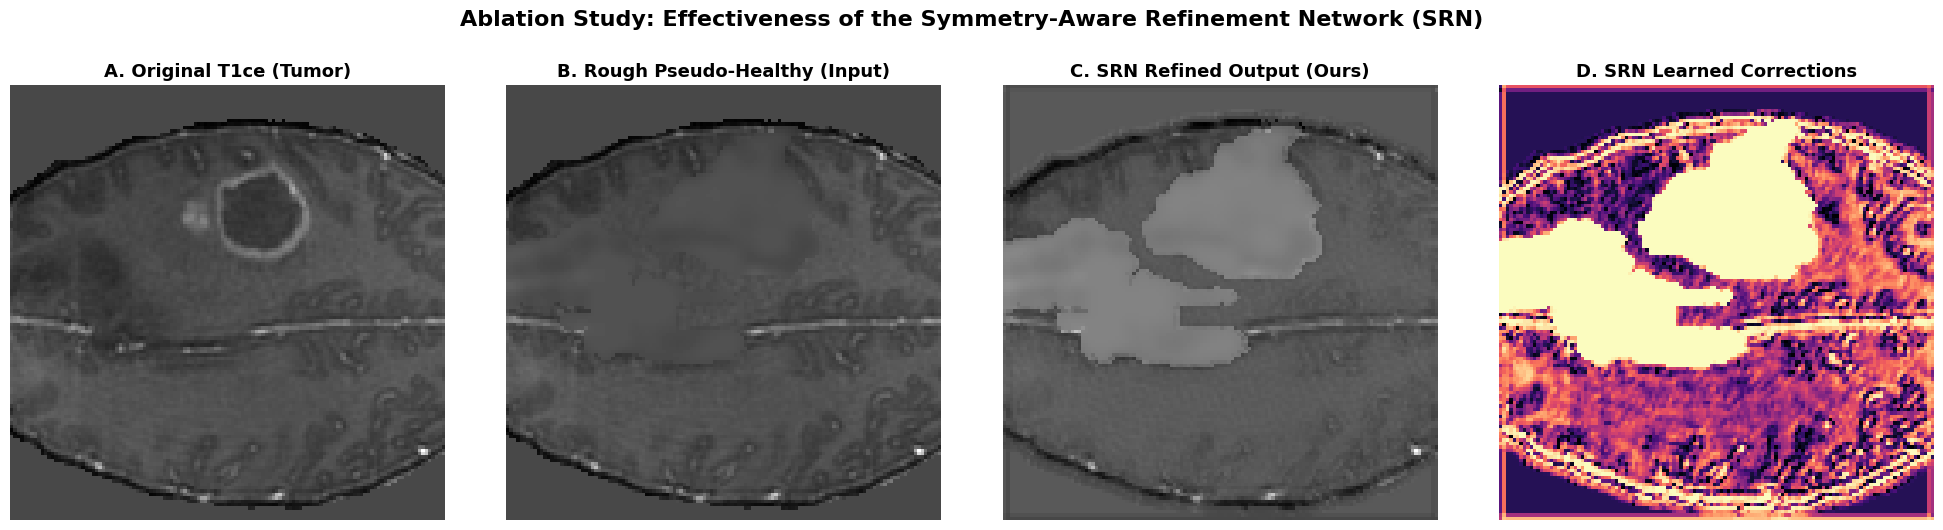

In [ ]:
def show_srn_ablation():
    """Shows the internal workings of the Symmetry Refinement Network."""
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = SEGNET().to(device)
    model.load_state_dict(torch.load(os.path.join(CKPT_DIR, 'best_model.pth'), map_location=device)['model'])
    model.eval()

    # Load random test slice
    data = np.load(os.path.join(LOCAL_PROC_DIR, f"{test_cases[2]}.npy"))
    sl = data[int(np.random.choice(np.where(data[:, 5, :, :].sum(axis=(1, 2)) > 150)[0]))]

    t1ce, rough_normal, seg = sl[1], sl[4], sl[5].astype(np.int64)

    # Push to model to intercept the Refined Normal image
    x_t = torch.from_numpy(np.stack(sl[:4])[np.newaxis].astype(np.float32)).to(device)
    n_t = torch.from_numpy(rough_normal[np.newaxis, np.newaxis].astype(np.float32)).to(device)

    with torch.no_grad():
        # Manually extract the refined output from our SRN module
        t1ce_guide = x_t[:, 1:2, :, :]
        refined_normal_tensor = model.refinement_net(n_t, t1ce_guide)
        refined_normal = refined_normal_tensor.squeeze().cpu().numpy()

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    axes[0].imshow(t1ce, cmap='gray')
    axes[0].set_title('A. Original T1ce (Tumor)', fontsize=13, fontweight='bold')
    axes[0].axis('off')

    axes[1].imshow(rough_normal, cmap='gray')
    axes[1].set_title('B. Rough Pseudo-Healthy (Input)', fontsize=13, fontweight='bold')
    axes[1].axis('off')

    axes[2].imshow(refined_normal, cmap='gray')
    axes[2].set_title('C. SRN Refined Output (Ours)', fontsize=13, fontweight='bold')
    axes[2].axis('off')

    # Calculate absolute difference to highlight what SRN fixed
    diff = np.abs(refined_normal - rough_normal)
    axes[3].imshow(diff, cmap='magma')
    axes[3].set_title('D. SRN Learned Corrections', fontsize=13, fontweight='bold')
    axes[3].axis('off')

    plt.suptitle("Ablation Study: Effectiveness of the Symmetry-Aware Refinement Network (SRN)", fontsize=16, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()

show_srn_ablation()

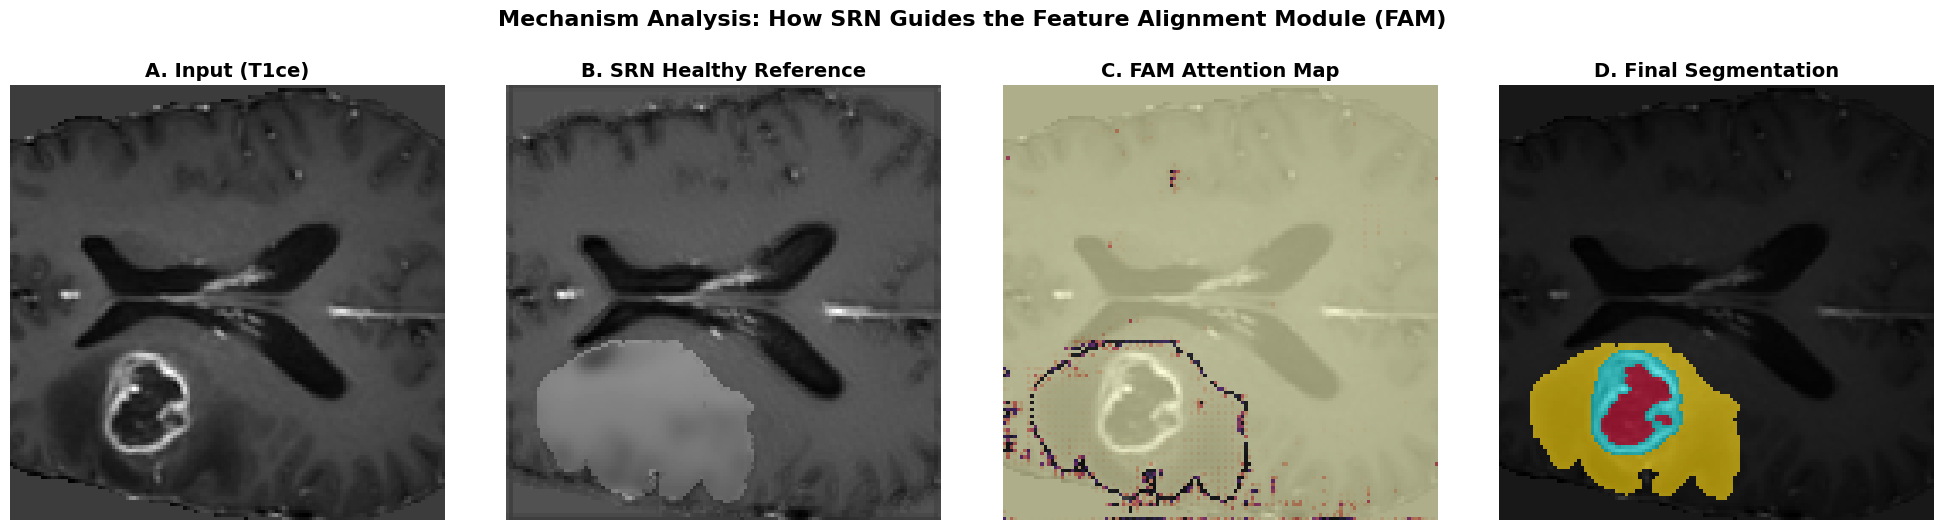

In [ ]:
def show_fam_mechanism():
    """
    Visualizes how the SRN Healthy Reference drives the FAM Attention Map
    to localize the tumor subclasses accurately.
    """
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    best_model_path = os.path.join(CKPT_DIR, 'best_model.pth')

    if not os.path.exists(best_model_path):
        print("Model checkpoint not found.")
        return

    # Load Model
    model = SEGNET().to(device)
    model.load_state_dict(torch.load(best_model_path, map_location=device)['model'])
    model.eval()

    # Find a good slice with a clear, large tumor
    data = np.load(os.path.join(LOCAL_PROC_DIR, f"{test_cases[0]}.npy"))
    seg_sums = data[:, 5, :, :].sum(axis=(1, 2))
    valid_slices = np.where(seg_sums > 300)[0]
    s_idx = valid_slices[len(valid_slices) // 2] # Middle of the tumor

    sl = data[s_idx]
    t1ce, rough_normal, seg = sl[1], sl[4], sl[5].astype(np.int64)

    # Prepare inputs
    x_t = torch.from_numpy(np.stack(sl[:4])[np.newaxis].astype(np.float32)).to(device)
    n_t = torch.from_numpy(rough_normal[np.newaxis, np.newaxis].astype(np.float32)).to(device)

    with torch.no_grad():
        out, attns, _ = model(x_t, n_t)
        # Extract refined healthy reference directly from SRN
        refined_normal = model.refinement_net(n_t, x_t[:, 1:2, :, :]).squeeze().cpu().numpy()

    pred = out.squeeze(0).argmax(dim=0).cpu().numpy()

    # Extract the deepest Attention Map (FAM)
    attn_map = attns[-1].squeeze().cpu().numpy()
    attn_norm = (attn_map - attn_map.min()) / (attn_map.max() - attn_map.min() + 1e-8)

    # Color Mapping function for Prediction
    def apply_colors(label_map):
        rgb = np.zeros((128, 128, 3), dtype=np.float32)
        rgb[label_map == 1] = [0.86, 0.08, 0.24] # Crimson (Necrosis)
        rgb[label_map == 2] = [1.00, 0.84, 0.00] # Gold (Edema)
        rgb[label_map == 3] = [0.00, 0.81, 0.82] # Cyan (Active Tumor)
        return rgb

    # Plotting
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    # A. Input T1ce
    axes[0].imshow(t1ce, cmap='gray')
    axes[0].set_title('A. Input (T1ce)', fontsize=14, fontweight='bold')
    axes[0].axis('off')

    # B. SRN Output (Pseudo-Healthy)
    axes[1].imshow(refined_normal, cmap='gray')
    axes[1].set_title('B. SRN Healthy Reference', fontsize=14, fontweight='bold')
    axes[1].axis('off')

    # C. FAM Attention Map (Overlay on Input)
    axes[2].imshow(t1ce, cmap='gray')
    axes[2].imshow(attn_norm, cmap='magma', alpha=0.6)
    axes[2].set_title('C. FAM Attention Map', fontsize=14, fontweight='bold')
    axes[2].axis('off')

    # D. Final Prediction
    axes[3].imshow(t1ce, cmap='gray')
    axes[3].imshow(apply_colors(pred), alpha=0.6)
    axes[3].set_title('D. Final Segmentation', fontsize=14, fontweight='bold')
    axes[3].axis('off')

    plt.suptitle("Mechanism Analysis: How SRN Guides the Feature Alignment Module (FAM)", fontsize=16, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()

show_fam_mechanism()

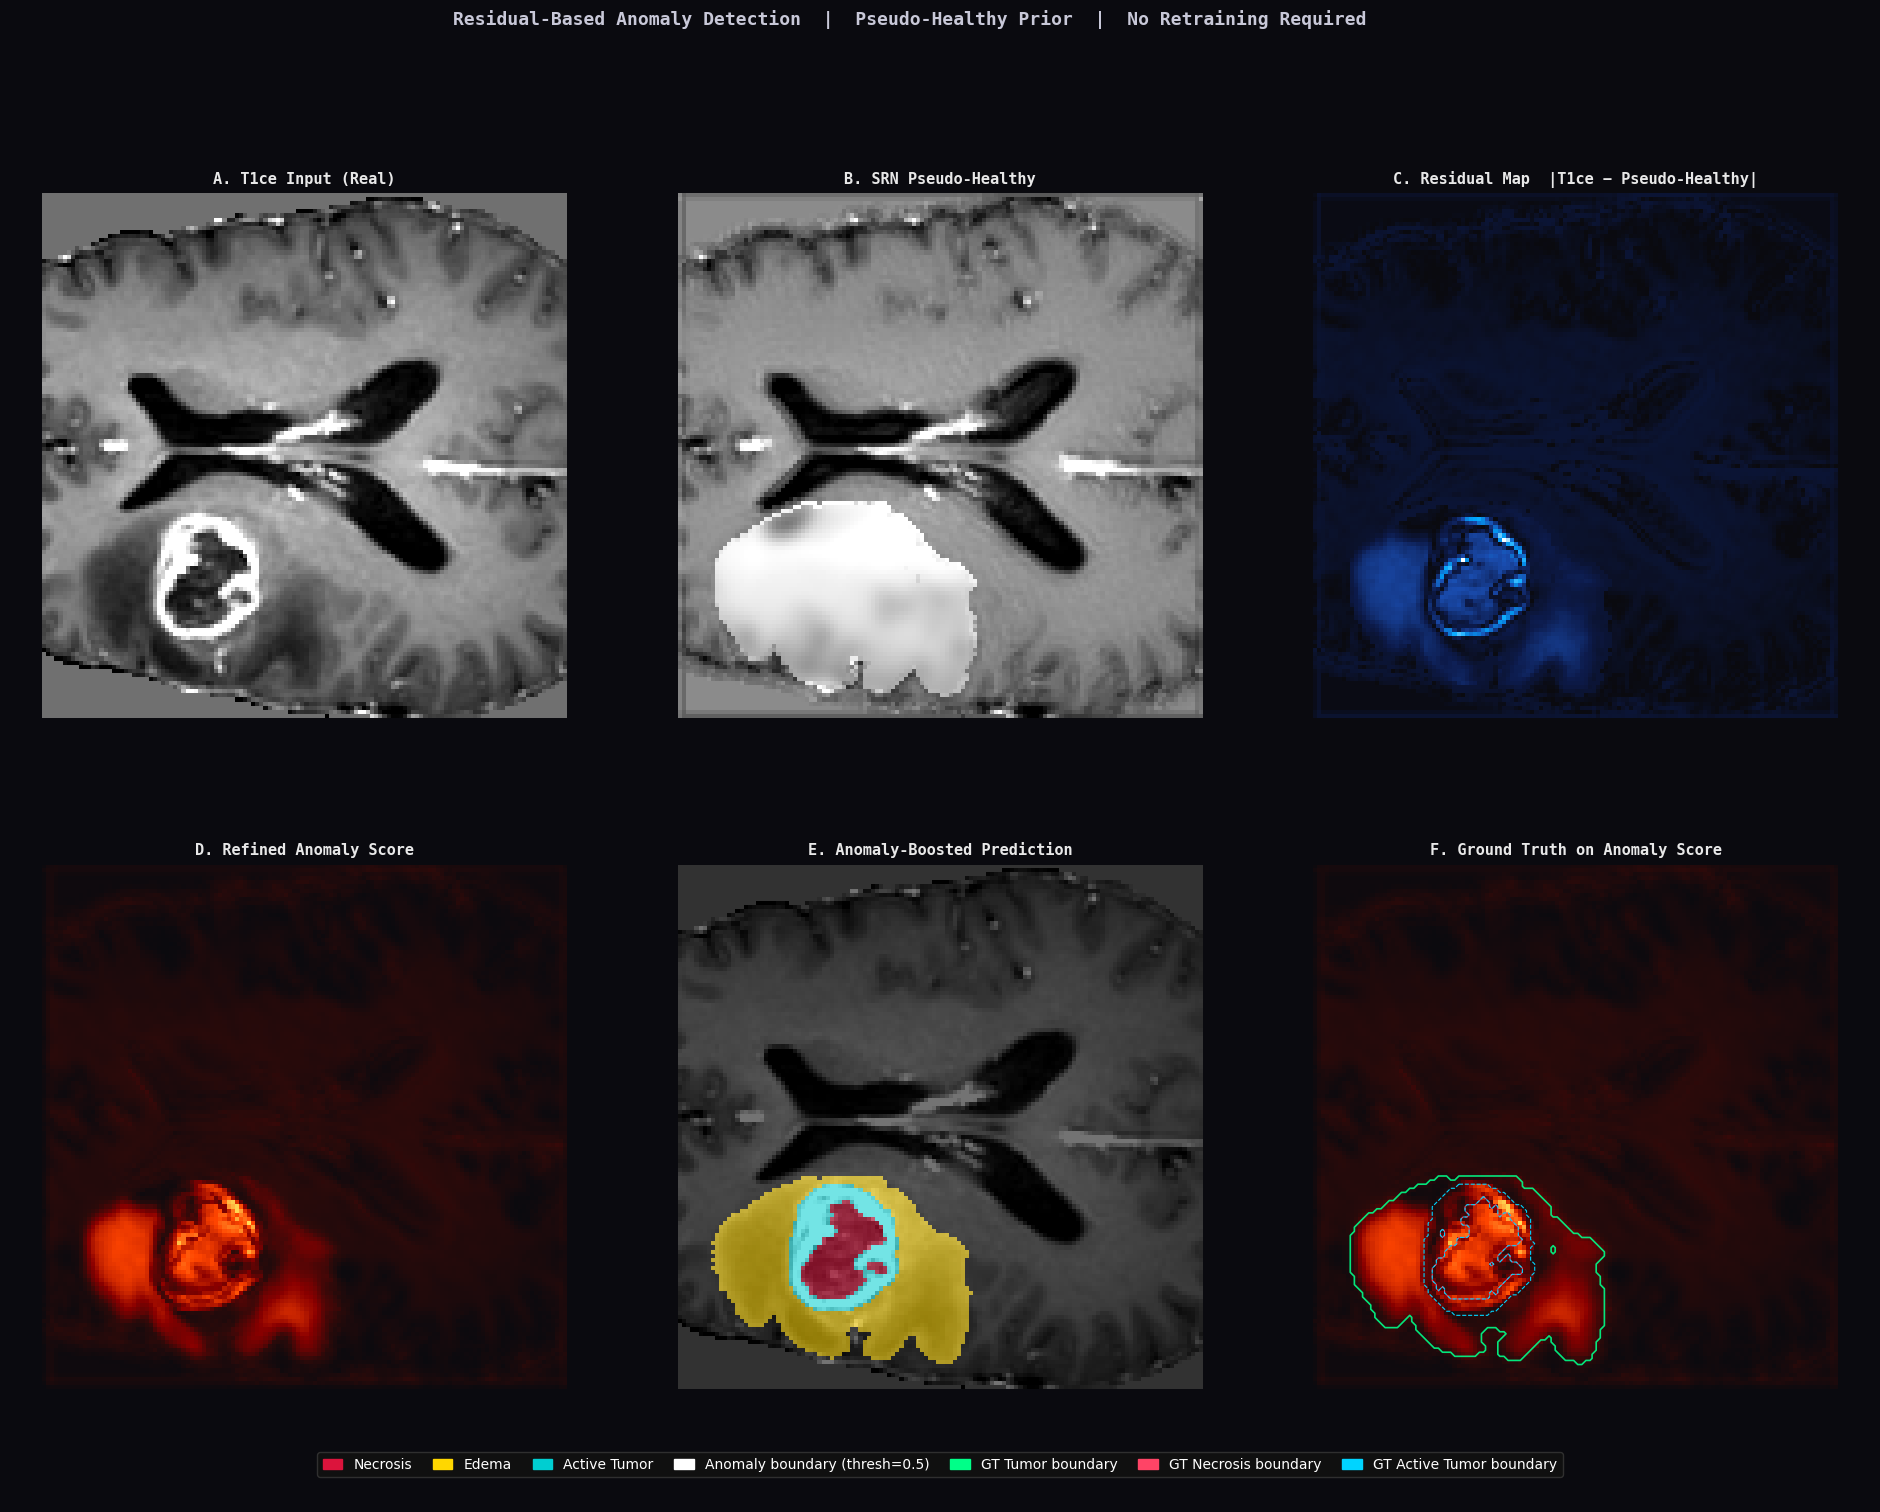


Visualization saved to: /content/drive/MyDrive/midterm_image/outputs/anomaly_detection.png

--- Anomaly Score Localisation Check ---
  Mean anomaly score inside  tumor region : 0.5723
  Mean anomaly score outside tumor region : 0.5219
  Tumor / Background ratio                : 1.10x
  (Ratio >> 1 means the anomaly map correctly highlights the tumor region)

  Threshold = 0.5
  Precision : 0.1299
  Recall    : 1.0000
  F1 Score  : 0.2299


In [ ]:
def show_anomaly_analysis():
    """
    6-panel anomaly detection visualisation:

    A. T1ce (real)              B. SRN Pseudo-Healthy
    C. Residual Map             D. Refined Anomaly Score
    E. Anomaly-Boosted Pred     F. GT vs Anomaly Score Overlay

    All computed from the saved checkpoint — no retraining required.
    """
    device          = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    best_model_path = os.path.join(CKPT_DIR, 'best_model.pth')

    if not os.path.exists(best_model_path):
        print("Model checkpoint not found. Please train the model first.")
        return

    # --- Load base model ---
    model = SEGNET().to(device)
    model.load_state_dict(torch.load(best_model_path, map_location=device)['model'])
    model.eval()

    # --- Instantiate anomaly module (weights random but module is deterministic
    #     for the residual path; the learned refinement is a bonus visualisation) ---
    anomaly_mod = ResidualAnomalyModule(in_ch=1, mid_ch=8, alpha=0.5).to(device)
    anomaly_mod.eval()

    # --- Deterministic slice selection: middle of the largest-tumor volume ---
    data         = np.load(os.path.join(LOCAL_PROC_DIR, f"{test_cases[0]}.npy"))
    seg_sums     = data[:, 5, :, :].sum(axis=(1, 2))
    valid_slices = np.where(seg_sums > 300)[0]
    s_idx        = int(valid_slices[len(valid_slices) // 2])
    sl           = data[s_idx]

    t1ce         = sl[1]
    rough_normal = sl[4]
    seg          = sl[5].astype(np.int64)

    x_t = torch.from_numpy(
        np.stack(sl[:4])[np.newaxis].astype(np.float32)
    ).to(device)
    n_t = torch.from_numpy(
        rough_normal[np.newaxis, np.newaxis].astype(np.float32)
    ).to(device)

    with torch.no_grad():
        # --- Standard inference ---
        out, attns, _ = model(x_t, n_t)          # (1, 4, H, W), list

        # --- Extract refined normal from SRN (same as show_srn_ablation) ---
        t1ce_guide     = x_t[:, 1:2, :, :]
        refined_normal = model.refinement_net(n_t, t1ce_guide)  # (1,1,H,W)

        # --- Compute residual and anomaly score ---
        residual_raw   = torch.abs(t1ce_guide - refined_normal)  # (1,1,H,W)
        boosted_logits, anomaly_score = anomaly_mod(out, t1ce_guide, refined_normal)

    # Convert to numpy
    t1ce_np        = t1ce
    pseudo_np      = refined_normal.squeeze().cpu().numpy()
    residual_np    = residual_raw.squeeze().cpu().numpy()
    anomaly_np     = anomaly_score.squeeze().cpu().numpy()
    pred_base      = out.squeeze(0).argmax(dim=0).cpu().numpy()
    pred_boosted   = boosted_logits.squeeze(0).argmax(dim=0).cpu().numpy()

    # Normalise residual for display
    res_disp = (residual_np - residual_np.min()) / (residual_np.max() - residual_np.min() + 1e-8)

    # --- Color helpers ---
    def apply_colors(label_map):
        rgb = np.zeros((128, 128, 3), dtype=np.float32)
        rgb[label_map == 1] = [0.86, 0.08, 0.24]  # Crimson : Necrosis
        rgb[label_map == 2] = [1.00, 0.84, 0.00]  # Gold    : Edema
        rgb[label_map == 3] = [0.00, 0.81, 0.82]  # Cyan    : Active Tumor
        return rgb

    residual_cmap = LinearSegmentedColormap.from_list(
        'res', ['#0a0a0f', '#0d1b4b', '#1a4db0', '#00a8ff', '#ffffff']
    )
    anomaly_cmap = LinearSegmentedColormap.from_list(
        'anom', ['#0a0a0f', '#2d0a0a', '#8b0000', '#ff4500', '#ffdd57']
    )

    vmin_t = np.percentile(t1ce_np, 2)
    vmax_t = np.percentile(t1ce_np, 98)

    # --- Build figure ---
    fig      = plt.figure(figsize=(24, 17), facecolor='#0a0a0f')
    outer_gs = gridspec.GridSpec(2, 1, figure=fig,
                                 height_ratios=[16, 1], hspace=0.06)
    panel_gs = gridspec.GridSpecFromSubplotSpec(
        2, 3, subplot_spec=outer_gs[0],
        hspace=0.28, wspace=0.08
    )

    def make_ax(spec, title):
        ax = fig.add_subplot(spec)
        ax.set_facecolor('#0a0a0f')
        ax.set_title(title, color='#e8e8e8', fontsize=11,
                     fontweight='bold', fontfamily='monospace', pad=7)
        ax.axis('off')
        return ax

    # A — Real T1ce
    ax_a = make_ax(panel_gs[0, 0], 'A. T1ce Input (Real)')
    ax_a.imshow(t1ce_np, cmap='gray', vmin=vmin_t, vmax=vmax_t)

    # B — SRN Pseudo-Healthy
    ax_b = make_ax(panel_gs[0, 1], 'B. SRN Pseudo-Healthy')
    ax_b.imshow(pseudo_np, cmap='gray',
                vmin=np.percentile(pseudo_np, 2),
                vmax=np.percentile(pseudo_np, 98))

    # C — Raw Residual Map  |T1ce - Pseudo|
    ax_c = make_ax(panel_gs[0, 2], 'C. Residual Map  |T1ce − Pseudo-Healthy|')
    ax_c.imshow(res_disp, cmap=residual_cmap)

    # D — Refined Anomaly Score  (after learned conv)
    ax_d = make_ax(panel_gs[1, 0], 'D. Refined Anomaly Score')
    ax_d.imshow(anomaly_np, cmap=anomaly_cmap)
    # Contour at 0.5 threshold to show the detected anomaly boundary
    ax_d.contour(anomaly_np, levels=[0.5], colors=['#ffffff'], linewidths=0.8, alpha=0.7)

    # E — Anomaly-Boosted Prediction vs Ground Truth
    ax_e = make_ax(panel_gs[1, 1], 'E. Anomaly-Boosted Prediction')
    ax_e.imshow(t1ce_np, cmap='gray', vmin=vmin_t, vmax=vmax_t)
    ax_e.imshow(apply_colors(pred_boosted), alpha=0.55)

    # F — GT overlay on anomaly score  (does the anomaly map find the tumor?)
    ax_f = make_ax(panel_gs[1, 2], 'F. Ground Truth on Anomaly Score')
    ax_f.imshow(anomaly_np, cmap=anomaly_cmap)
    # Draw GT tumor boundary as a contour — good overlap = good detection
    tumor_binary = (seg > 0).astype(np.float32)
    ax_f.contour(tumor_binary, levels=[0.5], colors=['#00ff88'],
                 linewidths=1.2, alpha=0.9)
    ax_f.contour((seg == 1).astype(float), levels=[0.5],
                 colors=['#ff4466'], linewidths=0.8, linestyles='dashed')
    ax_f.contour((seg == 3).astype(float), levels=[0.5],
                 colors=['#00d4ff'], linewidths=0.8, linestyles='dashed')

    # --- Legend strip ---
    ax_leg = fig.add_subplot(outer_gs[1])
    ax_leg.set_facecolor('#0a0a0f')
    ax_leg.axis('off')

    legend_patches = [
        mpatches.Patch(color='#dc143c', label='Necrosis'),
        mpatches.Patch(color='#ffd700', label='Edema'),
        mpatches.Patch(color='#00ced1', label='Active Tumor'),
        mpatches.Patch(color='#ffffff', label='Anomaly boundary (thresh=0.5)'),
        mpatches.Patch(color='#00ff88', label='GT Tumor boundary'),
        mpatches.Patch(color='#ff4466', label='GT Necrosis boundary'),
        mpatches.Patch(color='#00d4ff', label='GT Active Tumor boundary'),
    ]
    ax_leg.legend(handles=legend_patches, loc='center', ncol=7,
                  fontsize=10, facecolor='#111111', edgecolor='#333333',
                  labelcolor='white', framealpha=0.9,
                  handlelength=1.4, columnspacing=1.5)

    # --- Main title ---
    fig.text(
        0.5, 0.988,
        'Residual-Based Anomaly Detection  |  Pseudo-Healthy Prior  |  No Retraining Required',
        ha='center', va='top', color='#c8c8d8', fontsize=13,
        fontweight='bold', fontfamily='monospace'
    )

    out_path = os.path.join(OUT_DIR, 'anomaly_detection.png')
    plt.savefig(out_path, dpi=150, bbox_inches='tight', facecolor='#0a0a0f')
    plt.show()
    print(f"\nVisualization saved to: {out_path}")

    # --- Quantitative check: how well does the anomaly score localise the tumor? ---
    tumor_mask = seg > 0
    bg_mask    = ~tumor_mask
    print("\n--- Anomaly Score Localisation Check ---")
    print(f"  Mean anomaly score inside  tumor region : {anomaly_np[tumor_mask].mean():.4f}")
    print(f"  Mean anomaly score outside tumor region : {anomaly_np[bg_mask].mean():.4f}")
    ratio = anomaly_np[tumor_mask].mean() / (anomaly_np[bg_mask].mean() + 1e-8)
    print(f"  Tumor / Background ratio                : {ratio:.2f}x")
    print(f"  (Ratio >> 1 means the anomaly map correctly highlights the tumor region)")

    # Threshold the anomaly map and compute overlap with GT tumor mask
    thresh     = 0.5
    detected   = anomaly_np > thresh
    precision  = (detected & tumor_mask).sum() / (detected.sum() + 1e-8)
    recall     = (detected & tumor_mask).sum() / (tumor_mask.sum() + 1e-8)
    f1         = 2 * precision * recall / (precision + recall + 1e-8)
    print(f"\n  Threshold = {thresh}")
    print(f"  Precision : {precision:.4f}")
    print(f"  Recall    : {recall:.4f}")
    print(f"  F1 Score  : {f1:.4f}")

show_anomaly_analysis()